Click 'Choose Files' below to upload your image from the internet:


Saving greythird.webp to greythird.webp


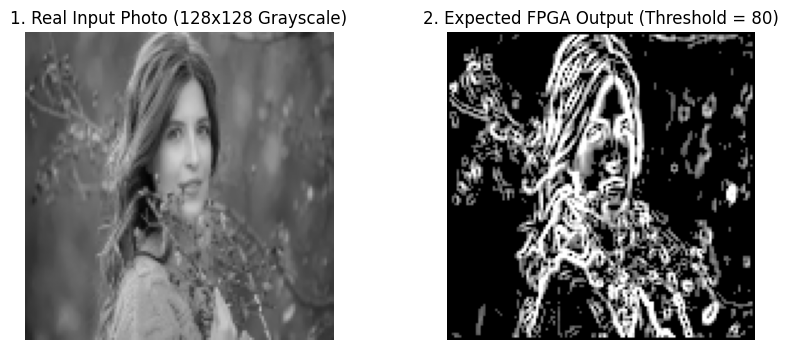

Success! Saved real photo into 'input_gray.mem' and 'golden_sobel.mem' (16384 lines each).


In [1]:
import numpy as np
import cv2
import urllib.request
import matplotlib.pyplot as plt
from skimage import data  # Built-in real photographs (no broken web links!)
from google.colab import files

# ==============================================================================
# 1. CHOOSE YOUR IMAGE SOURCE
# ==============================================================================
UPLOAD_MY_OWN_PHOTO = True  # Set to True to upload any image from your PC!
IMAGE_URL = "/content/Render_0002.jpg"               # Or paste any direct image URL here (leave "" for default real photo)

WIDTH = 128
HEIGHT = 128
THRESHOLD = 80               # Lower threshold (80) picks up finer details in real photos

# ==============================================================================
# 2. LOAD THE REAL IMAGE & CONVERT TO 128x128 GRAYSCALE
# ==============================================================================
if UPLOAD_MY_OWN_PHOTO:
    print("Click 'Choose Files' below to upload your image from the internet:")
    uploaded = files.upload()
    filename = list(uploaded.keys())[0]
    bgr_img = cv2.imread(filename)
    raw_gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
elif IMAGE_URL != "":
    req = urllib.request.urlopen(IMAGE_URL)
    arr = np.asarray(bytearray(req.read()), dtype=np.uint8)
    bgr_img = cv2.imdecode(arr, cv2.IMREAD_COLOR)
    raw_gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
else:
    # Loads the classic real-world 'Cameraman' photograph built into Python scikit-image
    print("Loading real-world 'Cameraman' test photograph...")
    raw_gray = data.camera()

# Resize to 128x128 so Vivado XSim simulates all 16,384 pixels in < 1 second
gray_img = cv2.resize(raw_gray, (WIDTH, HEIGHT), interpolation=cv2.INTER_AREA)

# ==============================================================================
# 3. RUN HARDWARE-EXACT SOBEL EDGE DETECTION (Our Answer Key)
# ==============================================================================
golden_sobel = np.zeros((HEIGHT, WIDTH), dtype=np.uint8)
p = gray_img.astype(np.int32)

for r in range(1, HEIGHT - 1):
    for c in range(1, WIDTH - 1):
        win = p[r-1 : r+2, c-1 : c+2]

        # Stage 1: Directional additions (same as SystemVerilog shift-and-add)
        gx_right = win[0, 2] + (2 * win[1, 2]) + win[2, 2]
        gx_left  = win[0, 0] + (2 * win[1, 0]) + win[2, 0]

        gy_top   = win[0, 0] + (2 * win[0, 1]) + win[0, 2]
        gy_bot   = win[2, 0] + (2 * win[2, 1]) + win[2, 2]

        # Stage 2: Signed Horizontal (Gx) and Vertical (Gy) gradients
        gx = gx_right - gx_left
        gy = gy_top   - gy_bot

        # Stage 3: Manhattan Magnitude |Gx| + |Gy| and Thresholding
        mag = abs(gx) + abs(gy)

        if mag >= THRESHOLD:
            golden_sobel[r, c] = 255 if (mag > 255) else mag
        else:
            golden_sobel[r, c] = 0

# ==============================================================================
# 4. DISPLAY REAL PHOTO vs. SOBEL EDGE OUTPUT
# ==============================================================================
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.title(f"1. Real Input Photo ({WIDTH}x{HEIGHT} Grayscale)")
plt.imshow(gray_img, cmap='gray', vmin=0, vmax=255)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.title(f"2. Expected FPGA Output (Threshold = {THRESHOLD})")
plt.imshow(golden_sobel, cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()

# ==============================================================================
# 5. EXPORT .MEM FILES FOR VIVADO SIMULATION
# ==============================================================================
with open("input_gray.mem", "w") as f_in, open("golden_sobel.mem", "w") as f_out:
    for r in range(HEIGHT):
        for c in range(WIDTH):
            f_in.write(f"{gray_img[r, c]:02X}\n")
            f_out.write(f"{golden_sobel[r, c]:02X}\n")

print(f"Success! Saved real photo into 'input_gray.mem' and 'golden_sobel.mem' ({WIDTH*HEIGHT} lines each).")